# DMS: material taxonomy and model classes

Source: Apple ml-dms-dataset, pinned in datasets/dms/source.json. The dataset annotations are CC BY-NC 4.0; the code/model have a separate licence.

These are dataset analyses, not camera training results.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / "datasets/dtd/source.json").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside a cloned Fitwell-AI repository")
plt.rcParams.update({"figure.facecolor": "#f5f1ea", "axes.facecolor": "#f5f1ea", "font.size": 11})
print("Repository:", ROOT.name)


Repository: repo


In [2]:
taxonomy = pd.read_csv(ROOT / "datasets/dms/taxonomy.csv")
model = pd.read_csv(ROOT / "datasets/dms/model_classes.csv")
assert taxonomy.label_id.is_unique
assert len(model) == 46 and model.model_channel.tolist() == list(range(46))
assert set(model.label_id) <= set(taxonomy.label_id)
print("Taxonomy entries:", len(taxonomy))
print("Semantic label IDs:", int(taxonomy.semantic_label.sum()))
print("Pretrained model output classes:", len(model))
print(model.to_string(index=False))

Taxonomy entries: 57
Semantic label IDs: 52
Pretrained model output classes: 46
 model_channel  label_id         material_name       shortname
             0         1           Animal skin            hide
             1         2       Bone/teeth/horn            bone
             2         3             Brickwork           brick
             3         4             Cardboard       cardboard
             4         5            Carpet/rug          carpet
             5         6          Ceiling tile     ceilingtile
             6         7               Ceramic         ceramic
             7         8 Chalkboard/blackboard      chalkboard
             8         9               Clutter         clutter
             9        10              Concrete        concrete
            10        11        Cork/corkboard            cork
            11        12      Engineered stone engineeredstone
            12        13          Fabric/cloth          fabric
            13        15              

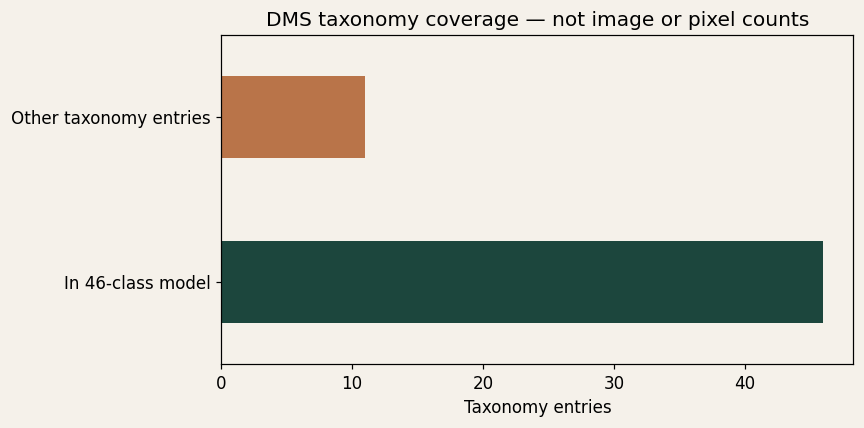

In [3]:
counts = pd.Series({"In 46-class model": int(taxonomy.in_dms46_model.sum()), "Other taxonomy entries": int((~taxonomy.in_dms46_model).sum())})
fig, ax = plt.subplots(figsize=(8, 4))
counts.plot.barh(ax=ax, color=["#1c463d", "#b97449"])
ax.set_xlabel("Taxonomy entries")
ax.set_title("DMS taxonomy coverage — not image or pixel counts")
plt.tight_layout()
plt.show()

        parent_directory  file_count  uncompressed_bytes
                  DMS_v1           3            22728840
      DMS_v1/labels/test       10168           183319653
     DMS_v1/labels/train       24251           449409296
DMS_v1/labels/validation       10138           182496585


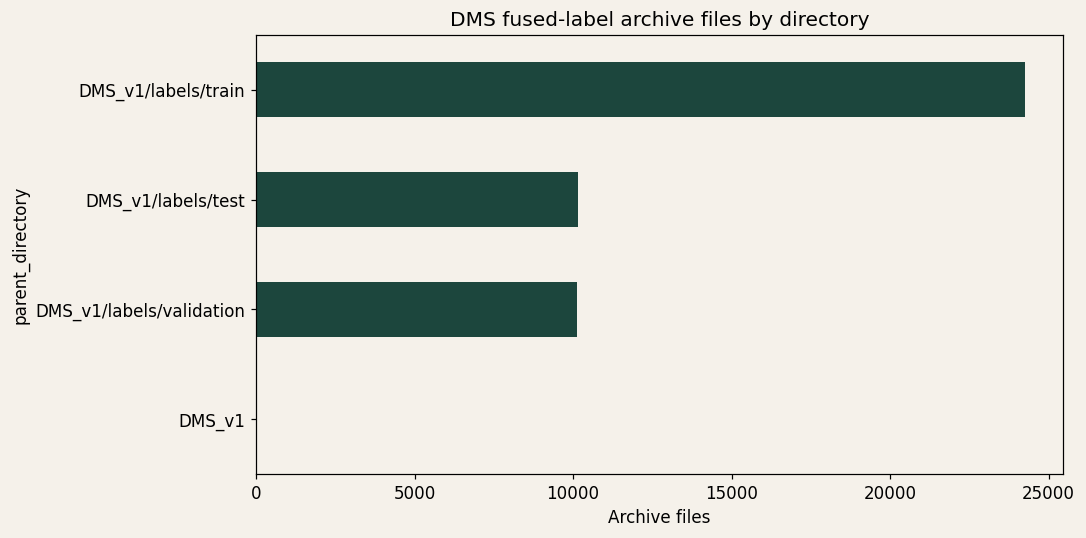

In [4]:
summary_path = ROOT / "datasets/dms/archive_summary.csv"
if summary_path.exists():
    summary = pd.read_csv(summary_path)
    print(summary.to_string(index=False))
    if not summary.empty:
        plot_data = summary.nlargest(12, "file_count").set_index("parent_directory")["file_count"]
        fig, ax = plt.subplots(figsize=(10, 5))
        plot_data.sort_values().plot.barh(ax=ax, color="#1c463d")
        ax.set_xlabel("Archive files")
        ax.set_title("DMS fused-label archive files by directory")
        plt.tight_layout()
        plt.show()
else:
    print("Archive summary not imported yet. No mask-frequency or accuracy graph is fabricated.")

Dataset label IDs and model output channel IDs differ: always use model_classes.csv. A mask file is not an RGB photo; training requires the paired Open Images photograph. Taxonomy counts do not measure how many images contain a material. No segmentation model was trained or evaluated by this notebook.